# Conversions: Existing Power Plants and Hydrogen from Electrolysis

The [basic tutorial](_2_basic_tutorial.ipynb) used one conversion: gas power plants, which turn natural gas into electricity and CO<sub>2</sub>. This notebook gives them some capacity that already exists at the start, and it adds a second energy carrier, hydrogen, which is produced from electricity:

| Component | New parameters and functions | What they do |
|---|---|---|
| Gas power plants | `stockCommissioning` | capacity that was built before the first investment period |
| | `esM.updateComponent` | changes parameters of a component that is already in the model |
| Electrolyzers | `commodityConversionFactors` | here: one commodity in, another one out |
| | `opexPerOperation` | cost per unit of operation |
| Hydrogen demand, hydrogen import | | a sink and a source for the new commodity |

## 1. The model of the basic tutorial, with hydrogen

The function `buildBasicTutorialModel` in the file [basicTutorialModel.py](basicTutorialModel.py) next to this notebook builds exactly the model of the basic tutorial. All commodities have to be known when the `EnergySystemModel` is created, so we pass the new commodity `hydrogen` and its unit right away with `commodityUnits`. `readData` reads one of the CSV files in `examples/data/twoRegions`.

In [1]:
import warnings

import pandas as pd

import fine as fn
from basicTutorialModel import (
    buildBasicTutorialModel,
    plotCapacityAndGeneration,
    readData,
)

warnings.filterwarnings("ignore")  # keeps the output of this tutorial readable

esM = buildBasicTutorialModel(commodityUnits={"hydrogen": "GW_H2"})

## 2. Existing gas power plants

In the basic tutorial, the system started empty. In reality, some capacity already exists at the start. Our data contains the combined cycle gas power plants that existed in Germany when the data set was made:

In [2]:
existingCapacity = readData("existingCapacity.csv")
existingCapacity.loc[["Gas power plants"]]  # GW

,north,south
technology,,
Gas power plants,6.8,0.6


Capacity built before the first investment period is given with **`stockCommissioning`**: a dictionary with the year in which the capacity was built (commissioned) as key and the capacity per region as value. FINE treats this capacity like capacity it has built itself, except that its investment is not part of the optimization (it has been paid already). It keeps the technical lifetime of the component (30 years for the gas power plants), so plants built in 2010 are still available in 2020 and 2030 and are decommissioned before 2040. The fixed operation costs (`opexPerCapacity`) are paid for them as long as they exist.

The gas power plants are already part of the model. Instead of building the model again, we change the component with **`esM.updateComponent`**: it takes the name of the component and a dictionary with the parameters to change, and keeps all other parameters.

In [3]:
esM.updateComponent(
    "Gas power plants",
    {"stockCommissioning": {2010: existingCapacity.loc["Gas power plants"]}},
)

## 3. Hydrogen

Industry needs hydrogen, e.g. to produce steel or chemicals. We assume that the industry starts to use it in 2030 with half of the demand of our data and needs all of it from 2040 on. Like the electricity demand, the hydrogen demand is a sink with a fixed hourly operation (in GW of hydrogen). Our data has the same demand in every hour:

In [4]:
hydrogenDemand = readData("hydrogenDemand.csv")
(hydrogenDemand.sum() / 1000).rename("Hydrogen demand [TWh per year]")

north    84.35880
south    54.77628
Name: Hydrogen demand [TWh per year], dtype: float64

In [5]:
esM.add(
    fn.Sink(
        esM=esM,
        name="Hydrogen demand",
        commodity="hydrogen",
        hasCapacityVariable=False,
        operationRateFix={
            2020: hydrogenDemand * 0,
            2030: hydrogenDemand * 0.5,
            2040: hydrogenDemand,
        },
    )
)

The hydrogen can be imported, e.g. by ship or pipeline from countries with cheap renewable energy. Like natural gas in the basic tutorial, the import is a source with a price (`commodityCost`), here 120 Euro per MWh in 2030 and 100 Euro per MWh in 2040:

In [6]:
esM.add(
    fn.Source(
        esM=esM,
        name="Hydrogen import",
        commodity="hydrogen",
        hasCapacityVariable=False,
        commodityCost={2020: 0.15, 2030: 0.12, 2040: 0.10},  # million Euro per GWh
    )
)

Or it can be produced in Germany by **electrolyzers**, which split water into hydrogen and oxygen using electricity. As a conversion, an electrolyzer consumes one commodity and produces another one:

- **`physicalUnit`** and **`commodityConversionFactors`**: we measure the capacity in GW of electricity consumed. Per unit of operation, an electrolyzer consumes 1 unit of electricity (factor −1) and produces 0.7 units of hydrogen (factor 0.7), so its efficiency is 70 %.
- **`opexPerOperation`**: a cost per unit of operation, here 2 Euro per MWh of electricity consumed (e.g. for water and wear). In contrast to `opexPerCapacity`, it is only paid when the electrolyzer runs.

Electrolyzers are expected to become much cheaper, so their investment falls from 1500 to 500 million Euro per GW.

In [7]:
esM.add(
    fn.Conversion(
        esM=esM,
        name="Electrolyzers",
        physicalUnit="GW_el",
        commodityConversionFactors={"electricity": -1, "hydrogen": 0.7},
        hasCapacityVariable=True,
        investPerCapacity={2020: 1500, 2030: 800, 2040: 500},  # million Euro per GW_el
        opexPerCapacity=30,  # million Euro per GW_el and year
        opexPerOperation=0.002,  # million Euro per GWh_el
        interestRate=0.08,
        economicLifetime=20,
    )
)

In this model, hydrogen cannot be transported between the two regions, so each region has to cover its own hydrogen demand. (A hydrogen pipeline would be a `Transmission` with the commodity `hydrogen`.)

## 4. Optimize

In [8]:
esM.aggregateTemporally(numberOfTypicalPeriods=8)

In [9]:
esM.optimize(
    timeSeriesAggregation=True,
    solver=fn.utils.ImplementedSolvers.STANDARD_SOLVER.value,
)

Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter QCPDual to value 1


Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26300.2))


CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]


... (71 outputs left out)

Solved with barrier


    2460    6.3570935e+05   0.000000e+00   0.000000e+00      1s


Solved in 2460 iterations and 0.72 seconds (0.64 work units)


Optimal objective  6.357093525e+05


## 5. Results

### Existing gas power plants

The optimization summary of the conversions shows how the existing plants enter the results:

In [10]:
gasPlants = pd.DataFrame(
    {
        year: esM.getOptimizationSummary("ConversionModel", outputLevel=1, ip=year)
        .loc["Gas power plants"]
        .xs("[GW_el]", level="Unit")
        .loc[["capacity", "commissioning", "decommissioning"]]
        .sum(axis=1)
        for year in esM.investmentPeriodNames
    }
)
gasPlants.columns.name = "Gas power plants [GW]"
gasPlants.astype(float).round(1)

Gas power plants [GW],2020,2030,2040
Property,,,
capacity,64.3,64.3,56.9
commissioning,56.9,0.0,0.0
decommissioning,0.0,0.0,7.4


In 2020, the capacity of 64.3 GW contains the 7.4 GW of existing plants, but only 56.9 GW are newly built (`commissioning`): the existing plants save investment. In 2040, the existing plants reach the end of their 30-year lifetime (`decommissioning`). The model does not replace them, because the gas power plants are needed less and less.

### Hydrogen supply

Where does the hydrogen come from? The electrolyzers' hydrogen production is their operation (electricity consumed) times 0.7:

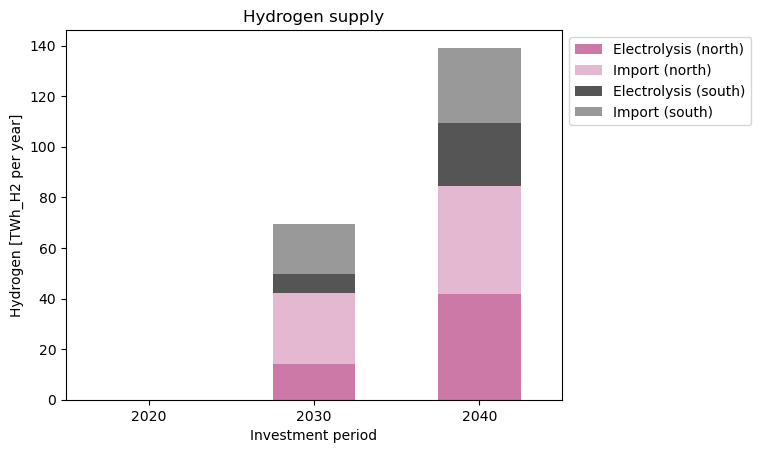

In [11]:
hydrogenSupply = pd.DataFrame(index=esM.investmentPeriodNames)
for year in esM.investmentPeriodNames:
    sourcesSinks = esM.getOptimizationSummary("SourceSinkModel", outputLevel=1, ip=year)
    conversions = esM.getOptimizationSummary("ConversionModel", outputLevel=1, ip=year)
    electrolysis = conversions.loc[("Electrolyzers", "operation")].iloc[0] * 0.7
    hydrogenImport = sourcesSinks.loc[("Hydrogen import", "operation")].iloc[0]
    for region in ["north", "south"]:
        hydrogenSupply.loc[year, f"Electrolysis ({region})"] = (
            electrolysis[region] / 1000
        )
        hydrogenSupply.loc[year, f"Import ({region})"] = hydrogenImport[region] / 1000

hydrogenSupply.plot.bar(
    stacked=True,
    color=["#CC79A7", "#E5B8D2", "#555555", "#999999"],
    rot=0,
    xlabel="Investment period",
    ylabel="Hydrogen [TWh_H2 per year]",
    title="Hydrogen supply",
).legend(loc="upper left", bbox_to_anchor=(1, 1));

Electrolysis covers about a third of the hydrogen demand in 2030 and almost half of it in 2040; the rest is imported. The capacity of the electrolyzers is just large enough to cover the whole hydrogen demand of their region in a single hour: in 2040, 13.8 GW of electricity produce the 9.6 GW of hydrogen that the north needs. Without a storage for hydrogen, producing more than is needed at the same moment would be of no use. Whenever electricity is scarce, the hydrogen is imported instead.

In the north, the electrolyzers run at full capacity on windy days, most of them in winter, and stand still on calm days:

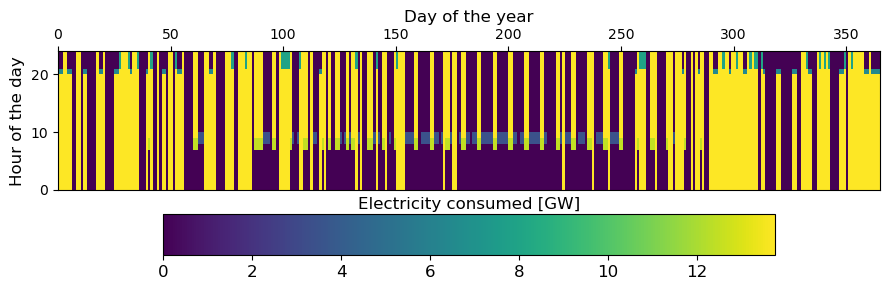

In [12]:
fn.plotOperationColorMap(
    esM,
    "Electrolyzers",
    "north",
    ip=2040,
    figsize=(9, 3),
    xlabel="Day of the year",
    ylabel="Hour of the day",
    zlabel="Electricity consumed [GW]",
);

Wind turbines and PV now also have to produce the electricity for the electrolyzers, about 95 TWh in 2040:

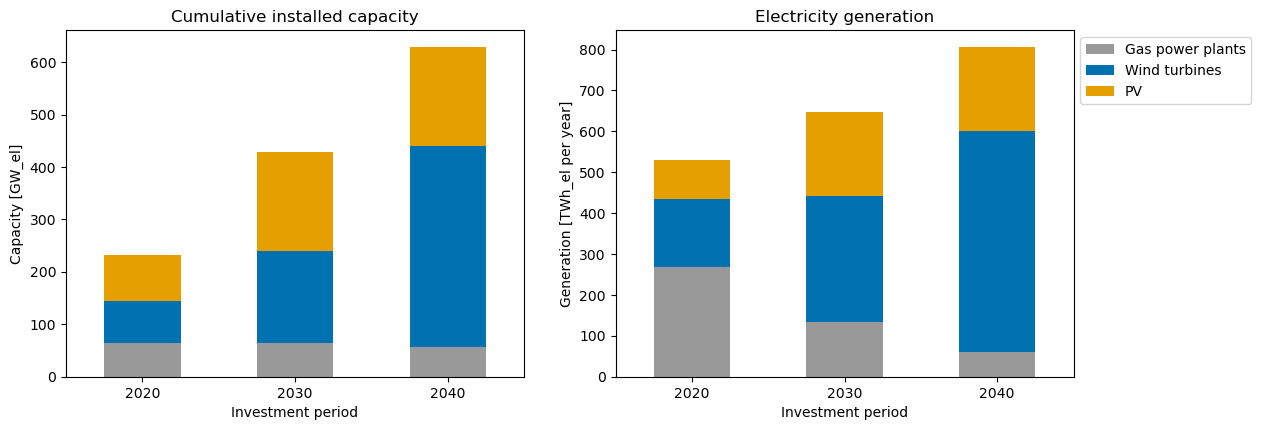

In [13]:
colors = {"Gas power plants": "#999999", "Wind turbines": "#0072B2", "PV": "#E69F00"}
capacity, generation = plotCapacityAndGeneration(esM, colors)

Compared with the basic tutorial, wind turbines and PV produce about 100 TWh more in 2040, but their capacities are almost the same. The electrolyzers mainly use electricity that would otherwise have been curtailed because nobody needed it at that moment.

## Things to try

- Make the hydrogen import more expensive (e.g. 150 Euro per MWh in 2040). How many more electrolyzers are built, and where does the additional electricity come from?
- Give the existing gas power plants a later commissioning year (e.g. 2015 instead of 2010). In which periods are they available now?
- Add a hydrogen pipeline between the regions as a `Transmission` (see the [Transmissions notebook](_7_transmissions.ipynb)). Which region produces the hydrogen then?

The next notebook, [Storages](_6_storages.ipynb), adds existing pumped hydro storage and seasonal hydrogen storage in salt caverns.